In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_pickle("..\data\data_charge_prep.pkl")

In [5]:
# Features that are already calculated in exploration:

# Add a column "endChargingTime" that holds the time when charging ended (doneChargingTime or disconnectTime if the doneChargingTime was null)
df["endChargingTime"] = df["doneChargingTime"].fillna(df["disconnectTime"])
# Charging duration (time actively charging)
df["chargingDurationMin"] = (df["endChargingTime"] - df["connectionTime"]).dt.total_seconds() / 60
# Idle time (time plugged in after charging finished)
df["blockingDurationMin"] = (df["disconnectTime"] - df["endChargingTime"]).dt.total_seconds() / 60

In [6]:
# proposed features:

# 1. Total time connected
df["connected_total_min"] = (df["disconnectTime"] - df["connectionTime"]).dt.total_seconds() / 60

# 2. Energy delivery rate (kW per hour), while considering 0 as a charging duration
df["energy_rate_kW"] = np.where(df["chargingDurationMin"] == 0, 0, df["kWhDelivered"] / (df["chargingDurationMin"] / 60))

# 3. cyclical encoding of connectionTime and disconnectTime with sine/cosine

df["connection_hour"] = df["connectionTime"].dt.hour + df["connectionTime"].dt.minute / 60.0
df["disconnect_hour"] = df["disconnectTime"].dt.hour + df["disconnectTime"].dt.minute / 60.0

df["connection_hour_sin"] = np.sin(2 * np.pi * df["connection_hour"] / 24) 
df["connection_hour_cos"] = np.cos(2 * np.pi * df["connection_hour"] / 24) 

df["disconnect_hour_sin"] = np.sin(2 * np.pi * df["disconnect_hour"] / 24)
df["disconnect_hour_cos"] = np.cos(2 * np.pi * df["disconnect_hour"] / 24)

# 4. isWeekday

df["connection_isWeekday"] = (df["connectionTime"].dt.dayofweek < 5).astype(int)

# 5. is User Registered?

df["isRegisteredUser"] = (df["userID"].notnull()).astype(int)

# TODO look at user input -> more features?

Double check energy_rate_kW

In [7]:
mean_value = df['energy_rate_kW'].mean()
std_value = df['energy_rate_kW'].std()

upper_bound = mean_value + 3 * std_value

# Extract outliers
outliers = df[(df['energy_rate_kW'] > upper_bound)]
print(f"Number of outliers: {len(outliers)}")

Number of outliers: 3


In [8]:
# drop energy_rate_kW because it causes too many outliers
df = df.drop('energy_rate_kW', axis=1)

<Axes: xlabel='connection_hour_sin', ylabel='Count'>

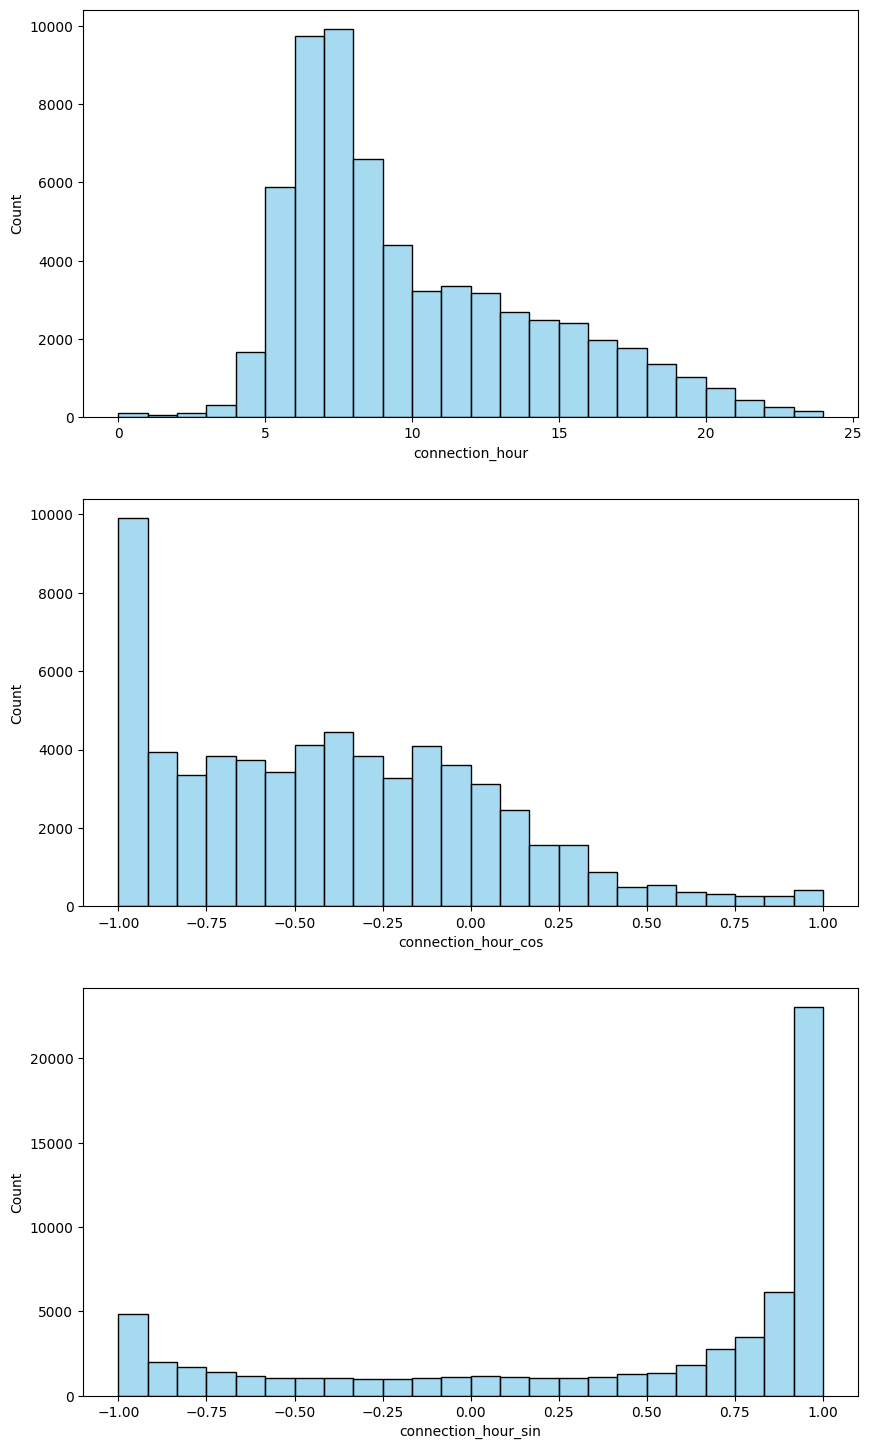

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(10, 18), sharex=False)

sns.histplot(df['connection_hour'].astype(float), bins=24, kde=False, color='skyblue', ax=axes[0])
sns.histplot(df['connection_hour_cos'].astype(float), bins=24, kde=False, color='skyblue', ax=axes[1])
sns.histplot(df['connection_hour_sin'].astype(float), bins=24, kde=False, color='skyblue', ax=axes[2])

In [12]:
import os
pd.to_pickle(df, "../data/data_features_clustering")